# Forelesning 7: Numerisk integrasjon

<div class="bilde-hoyre" style="width:50%">

![Kromatogram med integrerte topper](bilder/kromatogram_areal.png)

</div>

I dag skal vi

- tilnærme et integral som en sum av små arealer: rektangler og trapeser
- undersøke hvor raskt metodene **konvergerer** når vi bruker flere intervaller
- bruke ferdige funksjoner i SciPy
- integrere topper i et kromatogram

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate

## Repetisjon

<div class="oppgave">
    
1. Lag en funksjon som deriverer med framoverdifferansen, og en funksjon som bruker Newtons metode til å finne nullpunktet til en funksjon. 

2. Bruk tilnærmingen til den deriverte istedenfor den analytisk deriverte i Newtons metode og løs likningen $e^{-t} + t + 5 - \ln(0.006t + 1) = t^{0.3} + 10$.
</div>

In [7]:
def forward(f, x, h = 1E-8):
    return (f(x + h) - f(x))/h

def secant(f, x, tol = 1E-10):
    while abs(f(x)) > tol:
        x = x - f(x)/forward(f, x)
    return x

def f(t):
    return np.exp(-t) + t - np.log(0.006*t + 1) - t**0.3 - 10

secant(f, 10)

np.float64(12.187851075360781)

## Del 1: Rektangelmetoden

<div class="viktig">

Vi deler intervallet $[a, b]$ i $n$ figurer med bredde

$$h = \frac{b - a}{n}$$

og tilnærmer hver figur med et rektangel. Integralet er summen av arealene: $\int_a^b f(x)\,dx \approx \sum f(x_k) \cdot h$

</div>

<div class="bilde-midt" style="width:60%">

![Venstretilnærming med rektangler](bilder/venstretilnaerming.png)

</div>

### Det hele handler om tilnærminger

<div class="bilde-hoyre" style="width:45%">

![Sum og integral](bilder/sum_vs_integral.png)

</div>

| Når jeg skreller poteter | Når mora mi skreller poteter |
|:---:|:---:|
| $\displaystyle\sum_{k=1}^{n} f(x_k)\cdot\Delta x$ | $\displaystyle\int f(x)\,dx$ |

Summen er en tilnærming til integralet. Jo smalere rektangler, jo mindre «skrell» går til spille.

### Venstretilnærming
Vi integrerer $f(x) = \cos x + 2$ fra 2 til 12. Den eksakte verdien er $\left[\sin x + 2x\right]_2^{12} \approx 18{,}554$.

In [16]:
def f(x):
    return np.cos(x) + 2

a = 2		  # nedre integrasjonsgrense
b = 12        # øvre integrasjonsgrense
n = 100000        # antall rektangler
h = (b - a)/n # bredden av rektanglene

areal = 0
x = a

for i in range(n):
    areal = areal + f(x)*h
    x = x + h

print(areal)
    

18.5540666563309


<div class="oppgave">

**Prøv selv:** Vi pakker løkka inn i en funksjon med et ekstra argument `position`, som er 0 for venstre kant, 1 for høyre kant og 0,5 for midtpunktet. Fyll inn startverdien til `x`. Hvilken metode er best?

</div>

In [17]:
def rectangle(f, a, b, n, position=0):
    h = (b - a) / n
    area = 0
    x = a + position*h
    for k in range(n):
        area = area + f(x) * h
        x = x + h
    return area

exact = (np.sin(12) + 2*12) - (np.sin(2) + 2*2)

print("Left:    ", rectangle(f, 2, 12, 10, 0))
print("Right:   ", rectangle(f, 2, 12, 10, 1))
print("Midpoint:", rectangle(f, 2, 12, 10, 0.5))
print("Exact:   ", exact)

Left:     18.046675645664006
Right:    19.306676440943637
Midpoint: 18.492080387461613
Exact:    18.554129655173885


<div class="bilde-midt" style="width:95%">

![Venstre-, høyre- og midtpunktstilnærming](bilder/rektangelvarianter.png)

</div>

<div class="diskuter">

**Diskuter:** Se på figuren. Hvorfor blir midtpunktstilnærmingen så mye bedre? Hvilke funksjoner gir den et eksakt svar for?

</div>

## Del 2: Konvergens

Et numerisk svar bør ikke vurderes ut fra ett enkelt valg av $n$. Vi dobler antall intervaller og ser hvordan feilen endrer seg.

<div class="diskuter">

**Tipp først:** Hva skjer med feilen når vi dobler $n$?

</div>

In [18]:
for n in [10, 20, 40, 80, 160]:
    error_left = abs(rectangle(f, 2, 12, n, 0) - exact)
    error_mid = abs(rectangle(f, 2, 12, n, 0.5) - exact)
    print(f"n = {n:4d}   left: {error_left:.2e}   midpoint: {error_mid:.2e}")

n =   10   left: 5.07e-01   midpoint: 6.20e-02
n =   20   left: 2.85e-01   midpoint: 1.52e-02
n =   40   left: 1.50e-01   midpoint: 3.77e-03
n =   80   left: 7.69e-02   midpoint: 9.42e-04
n =  160   left: 3.89e-02   midpoint: 2.35e-04


<div class="viktig">

Når vi dobler $n$, blir feilen omtrent

- **halvert** for venstre- og høyretilnærmingen (feilen er proporsjonal med $1/n$)
- **fjerdedelt** for midtpunktstilnærmingen (feilen er proporsjonal med $1/n^2$)

Kontroller alltid et numerisk integral ved å øke $n$ og se om svaret stabiliserer seg.

</div>

## Del 3: Trapesmetoden

<div class="bilde-hoyre" style="width:22%">

![It's a trapezoidal rule](bilder/trapezoidal_rule_meme.jpg)

</div>

Rektanglene har en vannrett topp. Trekker vi i stedet en rett linje mellom funksjonsverdiene i de to endepunktene, får vi et **trapes**.

<div class="viktig">

Arealet av ett trapes med bredde $h$:

$$A_k = \frac{f(x_k) + f(x_{k+1})}{2}\cdot h$$

</div>

<div class="bilde-midt" style="width:50%">

![Rektangler og trapeser](bilder/integrasjonsmetoder.png)

</div>

<div class="oppgave">

**Prøv selv:** Kopier løkka fra `rectangle`, og endre den slik at den summerer trapeser i stedet for rektangler. Test på $f(x) = x^3$ fra 0 til 5, som har eksakt verdi 156,25.

</div>

In [20]:
def traps(f, a, b, n):
    h = (b - a) / n
    area = 0
    x = a
    for k in range(n):
        area = area + (f(x) + f(x + h))/2 * h
        x = x + h
    return area

exact = (np.sin(12) + 2*12) - (np.sin(2) + 2*2)

print("Left:    ", rectangle(f, 2, 12, 10, 0))
print("Right:   ", rectangle(f, 2, 12, 10, 1))
print("Midpoint:", rectangle(f, 2, 12, 10, 0.5))
print("Trapezoid:", traps(f, 2, 12, 10))
print("Exact:   ", exact)

Left:     18.046675645664006
Right:    19.306676440943637
Midpoint: 18.492080387461613
Trapezoid: 18.676676043303825
Exact:    18.554129655173885


<div class="viktig">

**Mønsteret:** Rektangler bruker en **konstant**, trapeser en **rett linje** og **Simpsons metode** et **andregradspolynom** mellom punktene.

</div>

<div class="bilde-midt" style="width:55%">

![Simpson's rule](bilder/simpsons_rule.png)

</div>

## Del 4: SciPy

<div class="bilde-hoyre" style="width:22%">

![Halvt semester på noe som fantes som bibliotek](bilder/bibliotek_meme.png)

</div>

<div class="viktig">

| Funksjon | Bruk |
|---|---|
| `integrate.trapezoid(y, x)` | måledata: arrayer med x- og y-verdier |
| `integrate.simpson(y, x=x)` | måledata, Simpsons metode |
| `integrate.quad(f, a, b)` | en funksjon vi kan evaluere hvor vi vil |

Eldre kode bruker navnene `trapz` og `simps`, som er fjernet i nyere SciPy.

</div>

In [24]:
def f(x):
    return np.cos(x) - 2*x
a = 2
b = 12

x = np.linspace(a, b, 1000)
y = f(x)

print(f"Trapes: {integrate.trapezoid(y, x)}")
print(f"Trapes: {integrate.simpson(y, x)}")
print(f"Trapes: {integrate.quad(f, a, b)}")

Trapes: -141.4458582717524
Trapes: -141.44587034513475
Trapes: (-141.4458703448261, 2.3126750808097117e-12)


### Integrasjon av måledata

En reaksjon utvikler CO₂-gass. En gassmåler registrerer hvor mange mL gass som strømmer ut per sekund, hvert 10. sekund. Det totale gassvolumet er arealet under kurven:

$$V = \int_0^{120} \text{gassfluks}\,dt$$

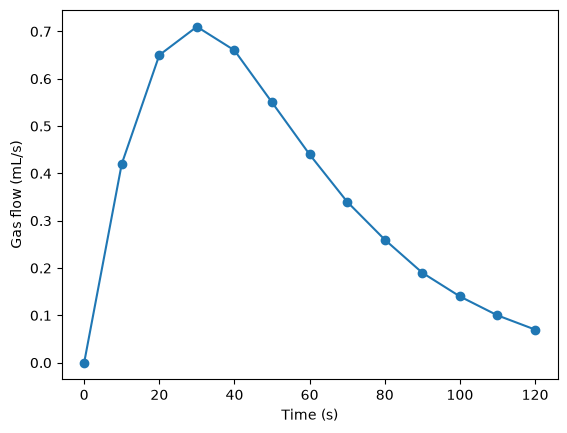

In [25]:
time = np.array([0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120])            # s
flow = np.array([0.00, 0.42, 0.65, 0.71, 0.66, 0.55, 0.44, 0.34, 0.26, 0.19, 0.14, 0.10, 0.07])   # mL/s

plt.plot(time, flow, "o-")
plt.xlabel("Time (s)")
plt.ylabel("Gas flow (mL/s)")
plt.show()

In [34]:
volum = 0
for i in range(len(flow)-1):
    dt = time[i+1] - time[i]
    volum = volum + flow[i]*dt

<div class="viktig">

Med måledata er steglengden bestemt av hvor ofte vi måler. Enheten til integralet er enheten til $y$ ganger enheten til $x$: mL/s · s = mL.

</div>

__Oppgaver__:
1. Integrer $f(x)=x^2-2x+4$ fra 2 til 8 med venstre-, høyre- og midtpunktstilnærming og trapesmetoden. Bruk først $n=10$ og deretter $n=100$, og sammenlikn med den analytiske verdien.
2. Plott den absolutte feilen som funksjon av $n$ for venstre-, midtpunkts- og trapesmetoden med logaritmiske akser. Hva forteller stigningen til linjene?
3. Et kalorimeter registrerer varmeeffekt $P(t)$ i watt hvert sekund. Forklar hvorfor $\int P(t)\,dt$ gir varme, lag et kunstig datasett og integrer det. Hvilken enhet får svaret?